**Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación - CICESE
Dr. Irvin Hussein López Nava

## ICD - 17: Ensambles y bagging

Sesión 17 del curso. Diapositivas: [icd-17-ensambles-bagging.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-17-ensambles-bagging.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-17-ensambles-bagging.ipynb)

La unidad 4 cerró con cinco modelos que, en el vino, empatan dentro del ruido entre pliegues. La unidad 5 pregunta qué pasa si, en lugar de elegir uno, los **combinamos**. Hoy vemos los ensambles en general y el **bagging**, con su versión más usada, **random forest**. Mañana, el boosting.

El notebook tiene seis partes. En la primera vemos por qué funciona combinar, con el jurado de Condorcet y la varianza de un promedio, y por qué deja de funcionar cuando los modelos se equivocan juntos. En la segunda combinamos por votación los cinco modelos de la unidad 4 en el vino. En la tercera hacemos bootstrap y bagging a mano con los 14 días. En la cuarta llevamos bagging y random forest al vino: cuánto estabilizan al árbol, el error fuera de la bolsa, el sorteo de variables, la importancia de las variables y el número de árboles. En la quinta vemos el stacking y su fuga más común. En la sexta, todo en una tabla.

---

### Preparación

Las bibliotecas de siempre. Todo el notebook usa scikit-learn; las bibliotecas de boosting llegan mañana.

In [1]:
import math
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
scikit-learn 1.9.1


Paleta y estilo de las sesiones anteriores. En las figuras, el naranja marca lo que sale mal o es optimista, y el azul, lo que se recomienda.

In [2]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})

SEMILLA = 42        # fija las particiones y los sorteos para que los resultados se repitan

---

### Los datos

- `weather.nominal.csv` son los 14 días de las sesiones 13 y 14; `weather.prueba.csv`, los 14 días de prueba de la sesión 15.
- `vinos-3clases.csv` es el vino de 3 clases de la sesión 12.

En las tres lecturas, la primera línea funciona tal cual desde la carpeta del repositorio clonado. En Colab, comenta la primera y descomenta la segunda.

In [3]:
nominal = pd.read_csv("datos/weather.nominal.csv")
# nominal = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.nominal.csv")

prueba = pd.read_csv("datos/weather.prueba.csv")
# prueba = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.prueba.csv")

vinos = pd.read_csv("datos/vinos-3clases.csv")
# vinos = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/vinos-3clases.csv")

print(f"Días: {len(nominal)} de entrenamiento y {len(prueba)} de prueba. Vinos: {len(vinos)}.")

Días: 14 de entrenamiento y 14 de prueba. Vinos: 1599.


---

## 1. ¿Por qué combinar?

### El jurado de Condorcet

Tenemos $L$ clasificadores independientes y cada uno acierta con probabilidad $p$. La votación por mayoría acierta si aciertan más de la mitad (diapositiva 16):

$$P_{\text{may}} = \sum_{k > L/2}^{L} \binom{L}{k}\, p^{k}\,(1-p)^{L-k}$$

Con $L = 3$ y $p = 0.7$, la mayoría acierta si aciertan dos o los tres: $3(0.7)^2(0.3) + (0.7)^3 = 0.441 + 0.343 = 0.784$.

In [4]:
def mayoria(L, p):
    # Probabilidad de que acierte la mayoría de L clasificadores independientes (L impar).
    return sum(math.comb(L, k) * p**k * (1 - p)**(L - k) for k in range(L // 2 + 1, L + 1))


print(f"L = 3, p = 0.7: 3(0.7)²(0.3) + (0.7)³ = {3 * 0.7**2 * 0.3:.3f} + {0.7**3:.3f} = {mayoria(3, 0.7):.3f}")
condorcet = pd.DataFrame({f"p = {p}": {L: mayoria(L, p) for L in [1, 3, 5, 11, 25, 51]} for p in [0.4, 0.55, 0.7]})
condorcet.index.name = "L"
condorcet.round(3)

L = 3, p = 0.7: 3(0.7)²(0.3) + (0.7)³ = 0.441 + 0.343 = 0.784


,p = 0.4,p = 0.55,p = 0.7
L,,,
1,0.400,0.550,0.700
3,0.352,0.575,0.784
5,0.317,0.593,0.837
11,0.247,0.633,0.922
25,0.154,0.694,0.983
51,0.074,0.764,0.999


**Lectura.** Con $p = 0.7$, la mayoría pasa de 0.700 con un clasificador a 0.784 con 3, 0.837 con 5, 0.922 con 11 y 0.983 con 25. Con $p = 0.55$ también sube, pero despacio: 0.694 con 25. Con $p = 0.4$ baja: 0.352 con 3 y 0.154 con 25. Votar amplifica lo que hay: si cada uno es mejor que el azar, la mayoría lo es más; si es peor, la mayoría es peor.

### Si se equivocan juntos

El teorema supone errores independientes. Un modelo de juguete para relajarlo (diapositiva 17): con probabilidad $\rho$, los $L$ clasificadores copian una misma decisión, que acierta con probabilidad $p$; con probabilidad $1 - \rho$, votan cada uno por su cuenta. Entonces

$$P = \rho\, p + (1-\rho)\, P_{\text{may}}(L)$$

Lo comprobamos con una simulación:

In [5]:
def simula_votos(L, p, rho, n=200_000, rng=None):
    # En cada caso, con probabilidad rho todos copian una decisión común; si no, cada uno acierta por su cuenta.
    rng = rng or np.random.default_rng(SEMILLA)
    comun = rng.random(n) < rho
    acierto_comun = rng.random(n) < p
    mayoria_propia = (rng.random((n, L)) < p).sum(axis=1) > L / 2
    return np.where(comun, acierto_comun, mayoria_propia).mean()


filas = []
for rho in [0, 0.3, 0.6, 1]:
    filas.append({"ρ": rho, **{f"L = {L}": rho * 0.7 + (1 - rho) * mayoria(L, 0.7) for L in [1, 5, 25, 101]},
                  "simulación, L = 25": simula_votos(25, 0.7, rho), "límite, L → ∞": rho * 0.7 + (1 - rho)})
pd.DataFrame(filas).set_index("ρ").round(3)

,L = 1,L = 5,L = 25,L = 101,"simulación, L = 25","límite, L → ∞"
ρ,,,,,,
0.0,0.7,0.837,0.983,1.00,0.983,1.00
0.3,0.7,0.796,0.898,0.91,0.898,0.91
0.6,0.7,0.755,0.813,0.82,0.813,0.82
1.0,0.7,0.700,0.700,0.70,0.700,0.70


**Lectura.** Con $\rho = 0.3$, la mayoría de 25 acierta 0.898, y la simulación da lo mismo. Ni con infinitos clasificadores pasa de $0.3(0.7) + 0.7(1) = 0.91$; con $\rho = 0.6$, el techo baja a 0.82. Lo que limita a la votación no es cuántos modelos hay, sino cuánto se parecen sus errores.

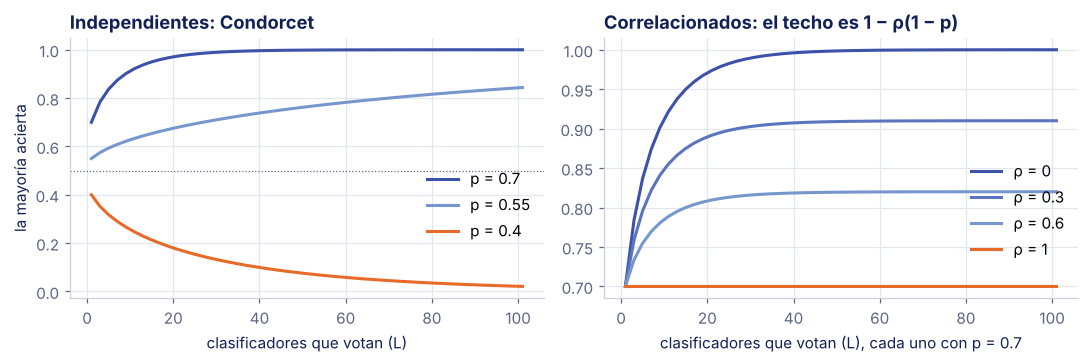

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
Ls = np.arange(1, 102, 2)
for p, color in [(0.7, AZUL_MEDIO), (0.55, AZUL), (0.4, NARANJA)]:
    ax1.plot(Ls, [mayoria(L, p) for L in Ls], color=color, linewidth=2, label=f"p = {p}")
ax1.axhline(0.5, color=GRIS, linewidth=0.8, linestyle=":")
ax1.set_xlabel("clasificadores que votan (L)")
ax1.set_ylabel("la mayoría acierta")
ax1.set_title("Independientes: Condorcet")
ax1.legend(loc="center right", bbox_to_anchor=(1.0, 0.36))
for rho, color in [(0, AZUL_MEDIO), (0.3, "#5A74BE"), (0.6, AZUL), (1, NARANJA)]:
    ax2.plot(Ls, [rho * 0.7 + (1 - rho) * mayoria(L, 0.7) for L in Ls], color=color, linewidth=2, label=f"ρ = {rho}")
ax2.set_xlabel("clasificadores que votan (L), cada uno con p = 0.7")
ax2.set_title("Correlacionados: el techo es 1 − ρ(1 − p)")
ax2.legend(loc="lower right", bbox_to_anchor=(1.0, 0.1))
plt.tight_layout()
plt.show()

### La varianza de un promedio

Cuando el ensamble promedia números (en regresión, o las probabilidades de la votación suave), la cuenta equivalente es la de la varianza (diapositiva 38). Si $L$ modelos tienen varianza $\sigma^2$ cada uno y correlación $\rho$ entre pares, de los $L^2$ términos de la varianza del promedio, $L$ son varianzas y $L(L-1)$ son covarianzas:

$$\mathrm{Var}\left(\frac{1}{L}\sum_{l=1}^{L} f_l\right) = \frac{1}{L^2}\left[L\sigma^2 + L(L-1)\,\rho\sigma^2\right] = \rho\,\sigma^2 + \frac{1-\rho}{L}\,\sigma^2$$

La simulamos con $\sigma^2 = 1$: cada $f_l$ es una parte común a todos, con peso $\sqrt{\rho}$, más una propia, con peso $\sqrt{1-\rho}$.

In [7]:
rng = np.random.default_rng(SEMILLA)
filas = []
for L in [1, 10, 100]:
    for rho in [0, 0.3]:
        f = np.sqrt(rho) * rng.normal(size=(20_000, 1)) + np.sqrt(1 - rho) * rng.normal(size=(20_000, L))
        filas.append({"L": L, "ρ": rho, "fórmula": rho + (1 - rho) / L, "simulación": f.mean(axis=1).var()})
pd.DataFrame(filas).round(3)

,L,ρ,fórmula,simulación
0,1,0.0,1.000,1.009
1,1,0.3,1.000,0.984
2,10,0.0,0.100,0.099
3,10,0.3,0.370,0.371
4,100,0.0,0.010,0.010
5,100,0.3,0.307,0.305


**Lectura.** Con $\rho = 0$, la varianza baja como $1/L$: 0.1 con 10 modelos y 0.01 con 100. Con $\rho = 0.3$ se queda en 0.37 con 10 y en 0.307 con 100, y nunca baja de 0.3. Agregar modelos solo achica el segundo término; para bajar el primero hay que bajar $\rho$. Es la idea de random forest (sección 4).

---

## 2. Votar con los cinco modelos de la unidad 4

El vino con el protocolo del notebook 13: 20 % para prueba con los duplicados del mismo lado, validación cruzada agrupada dentro del entrenamiento y la prueba una sola vez.

In [8]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

X = vinos.drop(columns="calidad")
y = vinos["calidad"]
grupos = pd.util.hash_pandas_object(vinos, index=False)      # filas idénticas, mismo grupo (notebook 12)

i_entrena, i_prueba = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y, grupos))
X_e, X_p = X.iloc[i_entrena], X.iloc[i_prueba]
y_e, y_p = y.iloc[i_entrena], y.iloc[i_prueba]
g_e = grupos.iloc[i_entrena]
pliegues = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
CLASES = np.array(["alta", "baja", "media"])                 # el orden de classes_ en scikit-learn
print(f"Entrenamiento: {len(i_entrena)} vinos; prueba: {len(i_prueba)}")

Entrenamiento: 1279 vinos; prueba: 320


Los cinco modelos son los de la tabla de la unidad 4 (notebook 16). Para la votación suave, cada uno tiene que dar probabilidades; el SVM las da calibrado, como en el notebook 16: `CalibratedClassifierCV` con `ensemble=False` y pliegues agrupados del conjunto con que se entrena.

`probas` entrena los cinco y devuelve sus probabilidades. La llamamos dos veces: una con todo el entrenamiento, para la prueba, y otra dentro de cada pliegue, para que cada vino de entrenamiento reciba las probabilidades de modelos que no lo vieron. Con esas predicciones **fuera del pliegue** validamos la votación, y en la sección 5 entrenamos el stacking.

In [9]:
def cinco_modelos(X_a, y_a, g_a):
    cortes = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X_a, y_a, g_a))
    return {
        "logística": make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)),
        "árbol elegido": DecisionTreeClassifier(random_state=0, max_depth=6, min_samples_leaf=5),
        "Naive Bayes": GaussianNB(),
        "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=51, weights="distance", p=1)),
        "SVM": CalibratedClassifierCV(make_pipeline(StandardScaler(), SVC(C=100, gamma=0.03)), ensemble=False, cv=cortes),
    }


def probas(X_a, y_a, g_a, X_b):
    # Entrena los cinco con (X_a, y_a) y devuelve, por modelo, sus probabilidades para X_b (n × 3).
    salida = {}
    for nombre, modelo in cinco_modelos(X_a, y_a, g_a).items():
        modelo.fit(X_a, y_a)
        assert list(modelo.classes_) == list(CLASES)
        salida[nombre] = modelo.predict_proba(X_b)
    return salida


P_prueba = probas(X_e, y_e, g_e, X_p)
P_oof = {nombre: np.zeros((len(X_e), 3)) for nombre in P_prueba}
for a, b in pliegues.split(X_e, y_e, g_e):
    for nombre, P in probas(X_e.iloc[a], y_e.iloc[a], g_e.iloc[a], X_e.iloc[b]).items():
        P_oof[nombre][b] = P
MODELOS = list(P_prueba)
print("Modelos:", ", ".join(MODELOS))

Modelos: logística, árbol elegido, Naive Bayes, kNN, SVM


### Votación dura y suave

En la **dura**, cada modelo vota por su clase más probable y gana la más votada. En la **suave**, se promedian las probabilidades y gana la mayor (diapositiva 25):

$$\hat{y}_{\text{dura}} = \arg\max_k \left|\{\, l : \hat{y}_l = k \,\}\right| \qquad\qquad \hat{y}_{\text{suave}} = \arg\max_k \frac{1}{L}\sum_{l=1}^{L} P_l(k \mid x)$$

In [10]:
def dura(P):
    # Gana la clase más votada; en un empate, la primera en orden alfabético, como VotingClassifier.
    votos = np.stack([P[m].argmax(axis=1) for m in MODELOS], axis=1)
    cuenta = np.stack([(votos == k).sum(axis=1) for k in range(3)], axis=1)
    return cuenta.argmax(axis=1), cuenta


def suave(P):
    return np.mean([P[m] for m in MODELOS], axis=0).argmax(axis=1)


def f1_por_pliegue(pred_oof):
    # El F1 macro de cada pliegue de validación: su media y su desviación, como cross_validate.
    f = [f1_score(y_e.iloc[b], CLASES[pred_oof[b]], average="macro") for _, b in pliegues.split(X_e, y_e, g_e)]
    return np.mean(f), np.std(f)


pred_dura, cuenta = dura(P_prueba)
pred_suave = suave(P_prueba)
filas = {m: (f1_por_pliegue(P_oof[m].argmax(axis=1)), CLASES[P_prueba[m].argmax(axis=1)]) for m in MODELOS}
filas["votación dura"] = (f1_por_pliegue(dura(P_oof)[0]), CLASES[pred_dura])
filas["votación suave"] = (f1_por_pliegue(suave(P_oof)), CLASES[pred_suave])
votacion = pd.DataFrame({nombre: {"F1 macro, validación": val[0], "desv. est.": val[1],
                                  "F1 macro, prueba": f1_score(y_p, pred, average="macro"),
                                  "aciertos": accuracy_score(y_p, pred)}
                         for nombre, (val, pred) in filas.items()}).T
print(f"La dura y la suave difieren en {(pred_dura != pred_suave).sum()} de {len(y_p)} vinos de prueba")
votacion.round(3)

La dura y la suave difieren en 17 de 320 vinos de prueba


,"F1 macro, validación",desv. est.,"F1 macro, prueba",aciertos
logística,0.562,0.022,0.573,0.619
árbol elegido,0.584,0.022,0.551,0.581
Naive Bayes,0.579,0.044,0.596,0.612
kNN,0.566,0.041,0.584,0.622
SVM,0.580,0.024,0.585,0.619
votación dura,0.588,0.022,0.595,0.631
votación suave,0.591,0.013,0.572,0.619


**Lectura.** Los cinco quedan como en el notebook 16, entre 0.562 y 0.584 de F1 macro en validación. El único cambio es el SVM: calibrado, cambia 3 de sus 320 predicciones y en prueba da 0.585 en lugar de 0.576. La dura y la suave difieren en 17 vinos. En prueba, la dura saca 0.595 y la suave 0.572; en validación, 0.588 y 0.591, junto al mejor de los cinco (0.584, el árbol) y dentro de la desviación entre pliegues. Combinar no ganó nada que se distinga del ruido.

¿Qué pasa en los vinos donde difieren? Dos ejemplos de la prueba:

In [11]:
def detalle(j):
    tabla = pd.DataFrame({m: P_prueba[m][j] for m in MODELOS}, index=CLASES).T
    tabla.loc["promedio"] = tabla.mean()
    tabla["voto"] = [CLASES[P_prueba[m][j].argmax()] for m in MODELOS] + [""]
    return tabla.round(3)


for j in [249, 218]:
    print(f"Vino {j} de la prueba (índice {X_p.index[j]}): es «{y_p.iloc[j]}». "
          f"Dura: {CLASES[pred_dura[j]]}, con {cuenta[j].max()} votos de 5; suave: {CLASES[pred_suave[j]]}")
    display(detalle(j))

Vino 249 de la prueba (índice 1231): es «baja». Dura: media, con 4 votos de 5; suave: baja


,alta,baja,media,voto
logística,0.026,0.478,0.497,media
árbol elegido,0.083,0.379,0.538,media
Naive Bayes,0.001,0.927,0.072,baja
kNN,0.000,0.344,0.656,media
SVM,0.073,0.323,0.604,media
promedio,0.037,0.490,0.473,


Vino 218 de la prueba (índice 1086): es «alta». Dura: alta, con 4 votos de 5; suave: media


,alta,baja,media,voto
logística,0.468,0.090,0.442,alta
árbol elegido,0.038,0.038,0.923,media
Naive Bayes,0.578,0.031,0.391,alta
kNN,0.420,0.223,0.357,alta
SVM,0.536,0.309,0.155,alta
promedio,0.408,0.138,0.454,


**Lectura.** En el 249, que es baja, cuatro modelos votan por media con poca seguridad (de 0.50 a 0.66), y Naive Bayes está muy seguro de baja (0.93): el promedio queda en 0.490 para baja y 0.473 para media, y la suave acierta. En el 218, que es alta, cuatro votan por alta, pero el árbol está muy seguro de media (0.92) y arrastra el promedio: 0.454 para media contra 0.408 para alta, y la suave falla. La suave escucha qué tan seguro está cada modelo, y eso solo conviene si sus probabilidades están calibradas. Las del árbol no lo están: su log-loss en el notebook 16 era de 3.133.

scikit-learn trae las dos con `VotingClassifier`. Con los mismos cinco modelos da las mismas predicciones:

In [12]:
from sklearn.ensemble import VotingClassifier

for voto, nuestra in [("hard", pred_dura), ("soft", pred_suave)]:
    sk = VotingClassifier(list(cinco_modelos(X_e, y_e, g_e).items()), voting=voto).fit(X_e, y_e)
    print(f"VotingClassifier(voting='{voto}') coincide con la nuestra en {(sk.predict(X_p) == CLASES[nuestra]).sum()} de {len(X_p)} vinos")

VotingClassifier(voting='hard') coincide con la nuestra en 320 de 320 vinos


VotingClassifier(voting='soft') coincide con la nuestra en 320 de 320 vinos


### Se equivocan juntos

La sección 1 dice dónde buscar la razón: ¿qué tan independientes son los errores de los cinco?

In [13]:
mal = pd.DataFrame({m: CLASES[P_prueba[m].argmax(axis=1)] != y_p.to_numpy() for m in MODELOS})
aciertos = 1 - mal.mean()
print(f"Fallan los cinco en {mal.all(axis=1).sum()} vinos ({mal.all(axis=1).mean():.1%}); "
      f"si sus errores fueran independientes, en {np.prod(1 - aciertos) * len(mal):.1f} ({np.prod(1 - aciertos):.1%})")
print(f"Aciertan los cinco en {(~mal).all(axis=1).sum()} ({(~mal).all(axis=1).mean():.1%}); "
      f"si fueran independientes, en {np.prod(aciertos):.1%}")
correlacion = mal.astype(float).corr()
print(f"Correlación media de los errores entre pares: {correlacion.to_numpy()[np.triu_indices(5, 1)].mean():.2f}")
correlacion.round(2)

Fallan los cinco en 58 vinos (18.1%); si sus errores fueran independientes, en 2.9 (0.9%)
Aciertan los cinco en 115 (35.9%); si fueran independientes, en 8.5%
Correlación media de los errores entre pares: 0.54


,logística,árbol elegido,Naive Bayes,kNN,SVM
logística,1.00,0.52,0.58,0.62,0.56
árbol elegido,0.52,1.00,0.43,0.53,0.49
Naive Bayes,0.58,0.43,1.00,0.48,0.52
kNN,0.62,0.53,0.48,1.00,0.62
SVM,0.56,0.49,0.52,0.62,1.00


**Lectura.** Los cinco fallan juntos en 58 de los 320 vinos (18 %); si sus errores fueran independientes, serían unos 3 (0.9 %). Y aciertan juntos en 36 % de los vinos, contra 8.5 % esperado. La correlación media entre sus errores es de 0.54: en el modelo de juguete, un $\rho$ así deja muy poco que ganar. Los cinco aprendieron de los mismos vinos y tropiezan con los mismos casos difíciles.

---

## 3. Bootstrap y bagging a mano: los 14 días

### Tres muestras bootstrap

Una muestra bootstrap saca $N$ ejemplos con reemplazo de los $N$ que hay: en bagging, $B = N$ (diapositivas 30 a 32). Tres muestras de los 14 días:

In [14]:
rng = np.random.default_rng(SEMILLA)
muestras = [rng.integers(0, 14, size=14) for _ in range(3)]      # posiciones 0 a 13: días 1 a 14
for k, m in enumerate(muestras, start=1):
    dias = sorted(nominal.Day.to_numpy()[m].tolist())
    print(f"Muestra {k}: {dias}  →  {len(set(dias))} días distintos; fuera de la bolsa: {sorted(set(nominal.Day) - set(dias))}")
pd.DataFrame([np.bincount(m, minlength=14) for m in muestras], index=["muestra 1", "muestra 2", "muestra 3"],
             columns=nominal.Day.rename("día"))

Muestra 1: [2, 2, 2, 3, 7, 7, 8, 10, 10, 11, 11, 11, 13, 14]  →  8 días distintos; fuera de la bolsa: [1, 4, 5, 6, 9, 12]
Muestra 2: [2, 3, 6, 6, 7, 8, 8, 10, 11, 11, 12, 12, 12, 13]  →  9 días distintos; fuera de la bolsa: [1, 4, 5, 9, 14]
Muestra 3: [1, 2, 3, 4, 4, 7, 7, 8, 8, 9, 11, 12, 13, 13]  →  10 días distintos; fuera de la bolsa: [5, 6, 10, 14]


día,1,2,3,4,5,6,7,8,9,10,11,12,13,14
muestra 1,0,3,1,0,0,0,2,1,0,2,3,0,1,1
muestra 2,0,1,1,0,0,2,1,2,0,1,2,3,1,0
muestra 3,1,1,1,2,0,0,2,2,1,0,1,1,2,0


**Lectura.** La muestra 1 trae tres veces los días 2 y 11, dos veces el 7 y el 10, y deja fuera seis: 1, 4, 5, 6, 9 y 12. Las otras dos dejan fuera 5 y 4.

¿Cuántos días quedan fuera, en promedio? Cada uno de los 14 sorteos esquiva un día dado con probabilidad 13/14:

In [15]:
p_fuera = (1 - 1 / 14) ** 14
print(f"P(un día no sale) = (13/14)^14 = {p_fuera:.3f}; en promedio quedan fuera 14 × {p_fuera:.3f} = {14 * p_fuera:.2f} días")
fuera = [14 - len(np.unique(rng.integers(0, 14, size=14))) for _ in range(100_000)]
print(f"Simulación con 100 000 muestras: {np.mean(fuera):.2f} días fuera, en promedio")
print(f"Con N grande, (1 − 1/N)^N → 1/e = {math.exp(-1):.3f}: cada muestra deja fuera 36.8 % de los datos")

N = len(X_e)
a, b = (np.unique(rng.integers(0, N, size=N)) for _ in range(2))
print(f"Dos muestras bootstrap de los {N} vinos de entrenamiento comparten {len(np.intersect1d(a, b)) / N:.1%} de los vinos; "
      f"(1 − 1/e)² = {(1 - math.exp(-1)) ** 2:.1%}")

P(un día no sale) = (13/14)^14 = 0.354; en promedio quedan fuera 14 × 0.354 = 4.96 días


Simulación con 100 000 muestras: 4.96 días fuera, en promedio
Con N grande, (1 − 1/N)^N → 1/e = 0.368: cada muestra deja fuera 36.8 % de los datos
Dos muestras bootstrap de los 1279 vinos de entrenamiento comparten 39.3% de los vinos; (1 − 1/e)² = 40.0%


**Lectura.** Un día no sale con probabilidad 0.354, y en promedio quedan fuera 4.96 de los 14. Con $N$ grande, la fracción tiende a $1/e = 0.368$: cada muestra usa 63.2 % de los datos distintos. Por eso las muestras no son independientes: dos de ellas comparten cerca de 40 % de los vinos (diapositiva 31). De ahí sale el $\rho$ de la sección 1.

### Tres árboles, un voto

En cada muestra entrenamos el ID3 del notebook 13, sin cambios, con los atributos nominales. Para clasificar los 14 días de prueba de la sesión 15, sus temperaturas y humedades se discretizan con los cortes de `weather.nominal.csv`: cool hasta 69 °F, mild de 70 a 76 y hot desde 77; la humedad es high por encima de 82 % (ver `datos/README.md`).

In [16]:
def entropia(clases):
    n = len(clases)
    return sum(-c / n * math.log2(c / n) for c in Counter(clases).values())


def ganancia(datos, atributo, objetivo="Play"):
    n = len(datos)
    return entropia(datos[objetivo]) - sum(len(parte) / n * entropia(parte[objetivo]) for _, parte in datos.groupby(atributo))


ATRIBUTOS = ["Outlook", "Temperature", "Humidity", "Wind"]
VALORES = {a: sorted(nominal[a].unique()) for a in ATRIBUTOS}


def id3(datos, atributos, objetivo="Play"):
    # El ID3 del notebook 13: crea también las ramas vacías, con la clase mayoritaria del nodo.
    clases = datos[objetivo]
    conteo = {True: int(clases.sum()), False: int((~clases).sum())}
    mayoritaria = conteo[True] >= conteo[False]
    if clases.nunique() == 1 or not atributos:
        return {"clase": mayoritaria, "conteo": conteo}
    mejor = max(atributos, key=lambda a: ganancia(datos, a, objetivo))
    resto = [a for a in atributos if a != mejor]
    ramas = {}
    for v in VALORES[mejor]:
        parte = datos[datos[mejor] == v]
        ramas[v] = {"clase": mayoritaria, "conteo": {True: 0, False: 0}} if len(parte) == 0 else id3(parte, resto, objetivo)
    return {"atributo": mejor, "ramas": ramas, "clase": mayoritaria, "conteo": conteo}


def predecir(nodo, ejemplo):
    while "atributo" in nodo:
        valor = ejemplo[nodo["atributo"]]
        if valor not in nodo["ramas"]:
            return nodo["clase"]
        nodo = nodo["ramas"][valor]
    return nodo["clase"]


def mostrar(nodo, sangria=""):
    for valor, hijo in nodo["ramas"].items():
        if "atributo" in hijo:
            print(f"{sangria}{nodo['atributo']} = {valor}")
            mostrar(hijo, sangria + "|   ")
        else:
            c = hijo["conteo"]
            print(f"{sangria}{nodo['atributo']} = {valor}: {hijo['clase']}  [{c[True]}+, {c[False]}−]")


def nominaliza(dias):
    salida = dias.copy()
    salida["Temperature"] = pd.cut(dias["Temperature"], bins=[0, 69, 76, 100], labels=["cool", "mild", "hot"]).astype(str)
    salida["Humidity"] = np.where(dias["Humidity"] > 82, "high", "normal")
    return salida


prueba_nominal = nominaliza(prueba)
real = prueba.Play.to_numpy()
votos = pd.DataFrame(index=prueba.Day)
for k, m in enumerate(muestras, start=1):
    arbol = id3(nominal.iloc[m].reset_index(drop=True), ATRIBUTOS)
    print(f"--- Árbol {k}")
    mostrar(arbol)
    votos[f"árbol {k}"] = [predecir(arbol, dia) for _, dia in prueba_nominal.iterrows()]
votos["voto"] = votos.sum(axis=1) >= 2
votos["real"] = real
print("\nAciertos en los 14 días de prueba:", votos.drop(columns="real").eq(votos["real"], axis=0).sum().to_dict())
votos.T

--- Árbol 1
Humidity = high
|   Outlook = overcast: True  [1+, 0−]
|   Outlook = rain: False  [0+, 1−]
|   Outlook = sunny: False  [0+, 4−]
Humidity = normal: True  [8+, 0−]
--- Árbol 2
Outlook = overcast: True  [6+, 0−]
Outlook = rain
|   Temperature = cool: False  [0+, 2−]
|   Temperature = hot: False  [0+, 0−]
|   Temperature = mild: True  [1+, 0−]
Outlook = sunny
|   Humidity = high: False  [0+, 3−]
|   Humidity = normal: True  [2+, 0−]
--- Árbol 3
Outlook = overcast: True  [6+, 0−]
Outlook = rain: True  [2+, 0−]
Outlook = sunny
|   Humidity = high: False  [0+, 4−]
|   Humidity = normal: True  [2+, 0−]

Aciertos en los 14 días de prueba: {'árbol 1': 10, 'árbol 2': 13, 'árbol 3': 11, 'voto': 12}


Day,15,16,17,18,19,20,21,22,23,24,25,26,27,28
árbol 1,False,True,False,True,False,False,True,False,True,True,True,True,True,True
árbol 2,False,True,True,True,False,False,True,True,True,True,True,True,False,True
árbol 3,False,True,True,True,False,True,True,True,True,True,True,True,True,True
voto,False,True,True,True,False,False,True,True,True,True,True,True,True,True
real,False,True,True,False,False,False,True,True,True,True,True,True,False,True


**Lectura.** Las tres muestras dan tres árboles distintos. El 1 ni siquiera empieza por Outlook: en su muestra, la humedad separa mejor. El 2 pregunta la temperatura en la rama rain: en su muestra, la temperatura y el viento separan igual de bien esos días, y en el empate gana la primera de la lista. El 3 ya no pregunta nada en esa rama: de los días rain, su muestra solo trae el 4, dos veces, y ese día sí se jugó. En prueba aciertan 10, 13 y 11 de 14, y su voto acierta 12.

¿Y con más árboles? Comparamos con el árbol ID3 de los 14 días:

In [17]:
arbol_14 = id3(nominal, ATRIBUTOS)
pred_14 = np.array([predecir(arbol_14, dia) for _, dia in prueba_nominal.iterrows()])
print(f"ID3 con los 14 días: {(pred_14 == real).sum()}/14; falla los días {prueba.Day[pred_14 != real].tolist()}")

rng_bolsa = np.random.default_rng(SEMILLA)          # la misma secuencia: los 3 primeros árboles son los de arriba
votos_si = np.zeros(14)
for t in range(1, 102):
    m = rng_bolsa.integers(0, 14, size=14)
    arbol = id3(nominal.iloc[m].reset_index(drop=True), ATRIBUTOS)
    votos_si += [predecir(arbol, dia) for _, dia in prueba_nominal.iterrows()]
    if t in (3, 11, 101):
        pred = votos_si > t / 2
        print(f"Bagging con {t:3d} árboles: {(pred == real).sum()}/14; falla los días {prueba.Day[pred != real].tolist()}")

ID3 con los 14 días: 12/14; falla los días [18, 27]
Bagging con   3 árboles: 12/14; falla los días [18, 27]
Bagging con  11 árboles: 12/14; falla los días [18, 27]


Bagging con 101 árboles: 12/14; falla los días [18, 27]


**Lectura.** El voto de 3, de 11 y de 101 árboles acierta 12 de 14, igual que el árbol de los 14 días, y falla los mismos días. El 18 es sunny con humedad normal y no se jugó; el 27, rain con viento débil y no se jugó. Contradicen la regla que aprenden casi todos los árboles (`datos/README.md` lo advierte: las etiquetas de prueba siguen el árbol J48 de la sesión 13 salvo en esos dos días), y votar no arregla un error que todos comparten (diapositiva 42). Con 14 días no hay mucho que ganar; en el vino sí.

---

## 4. Bagging y random forest en el vino

### El árbol se estabiliza

El experimento del notebook 13: dos modelos entrenados con mitades distintas del entrenamiento, con las gemelas juntas, 20 veces, y en cuántos vinos de prueba difieren. Usamos las mismas 20 particiones y agregamos dos bosques de 500 árboles: **bagging** de árboles completos y **random forest** (diapositiva 43). Tarda alrededor de un minuto.

In [18]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

rng = np.random.default_rng(SEMILLA)
unicos = pd.unique(g_e)
modelos = {
    "árbol completo": lambda: DecisionTreeClassifier(random_state=0),
    "árbol elegido": lambda: DecisionTreeClassifier(random_state=0, max_depth=6, min_samples_leaf=5),
    "regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)),
    "bagging, 500 árboles": lambda: BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=500,
                                                      random_state=0, n_jobs=-1),
    "random forest, 500 árboles": lambda: RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1),
}
desacuerdo = {nombre: [] for nombre in modelos}
f1_mitad = {nombre: [] for nombre in modelos}
inicio = time.perf_counter()
for _ in range(20):
    mitad = set(rng.permutation(unicos)[: len(unicos) // 2])
    en_mitad = g_e.isin(mitad).to_numpy()
    for nombre, crear in modelos.items():
        pa = crear().fit(X_e[en_mitad], y_e[en_mitad]).predict(X_p)
        pb = crear().fit(X_e[~en_mitad], y_e[~en_mitad]).predict(X_p)
        desacuerdo[nombre].append((pa != pb).mean())
        f1_mitad[nombre] += [f1_score(y_p, pa, average="macro"), f1_score(y_p, pb, average="macro")]
print(f"{time.perf_counter() - inicio:.0f} s")
estabilidad = pd.DataFrame({n: {"desacuerdo, promedio": np.mean(v), "mínimo": np.min(v), "máximo": np.max(v),
                                "F1 macro de cada mitad": np.mean(f1_mitad[n])} for n, v in desacuerdo.items()}).T
estabilidad.round(3)

62 s


,"desacuerdo, promedio",mínimo,máximo,F1 macro de cada mitad
árbol completo,0.481,0.428,0.525,0.494
árbol elegido,0.423,0.322,0.547,0.509
regresión logística,0.191,0.134,0.266,0.573
"bagging, 500 árboles",0.294,0.247,0.344,0.577
"random forest, 500 árboles",0.283,0.238,0.338,0.584


**Lectura.** Las tres primeras filas son las del notebook 13: 48 %, 42 % y 19 %. Dos bosques de 500 árboles difieren en 29 % de los vinos (bagging) y 28 % (random forest): promediar quitó casi la mitad de la inestabilidad del árbol, aunque no llega a la de la logística. Y aciertan más: con media muestra, el F1 macro de cada mitad sube de 0.494 con el árbol completo a 0.577 y 0.584. El desacuerdo no baja a cero porque cada bosque promedia árboles de muestras de su misma mitad: hereda lo que esa mitad tiene de particular.

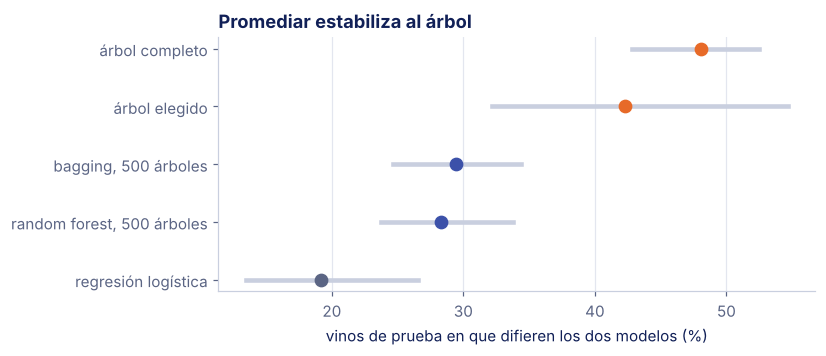

In [19]:
fig, ax = plt.subplots(figsize=(7, 3))
orden = ["regresión logística", "random forest, 500 árboles", "bagging, 500 árboles", "árbol elegido", "árbol completo"]
for i, nombre in enumerate(orden):
    fila = estabilidad.loc[nombre]
    color = NARANJA if nombre.startswith("árbol") else (AZUL_MEDIO if "500" in nombre else GRIS)
    ax.plot([fila["mínimo"] * 100, fila["máximo"] * 100], [i, i], color="#C9CFDF", linewidth=3)
    ax.plot(fila["desacuerdo, promedio"] * 100, i, "o", color=color, markersize=8)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlabel("vinos de prueba en que difieren los dos modelos (%)")
ax.set_title("Promediar estabiliza al árbol")
ax.grid(axis="y", visible=False)
plt.show()

### El error fuera de la bolsa

Cada vino queda fuera de cerca de 37 % de las muestras bootstrap: esos árboles no lo vieron. Si votan solo ellos, cada vino recibe una predicción honesta y se obtiene una validación gratis, el error **OOB** (*out-of-bag*, diapositiva 44). En scikit-learn se pide con `oob_score=True`; `oob_score_` es la exactitud, y `oob_decision_function_` trae las probabilidades, con las que calculamos el F1 macro.

In [20]:
from sklearn.model_selection import StratifiedKFold

def f1_oob(bosque, y_verdad):
    return f1_score(y_verdad, bosque.classes_[bosque.oob_decision_function_.argmax(axis=1)], average="macro")


bosque = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1, oob_score=True).fit(X_e, y_e)
pred_oob = bosque.classes_[bosque.oob_decision_function_.argmax(axis=1)]
cv_agrupada = cross_validate(RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1), X_e, y_e, groups=g_e,
                             cv=pliegues, scoring="f1_macro")["test_score"]
cv_usual = cross_validate(RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1), X_e, y_e,
                          cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA), scoring="f1_macro")["test_score"]

tam_grupo = g_e.map(g_e.value_counts()).to_numpy()
con_gemela = tam_grupo > 1
unico = ~g_e.duplicated().to_numpy()                       # un vino por grupo de duplicados
bosque_unicos = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1, oob_score=True).fit(X_e[unico], y_e[unico])

print(f"{con_gemela.sum()} de los {len(X_e)} vinos de entrenamiento tienen al menos una gemela; sin duplicados quedan {unico.sum()}")
print(f"Exactitud OOB en los vinos con gemela: {(pred_oob[con_gemela] == y_e.to_numpy()[con_gemela]).mean():.3f}; "
      f"en el resto: {(pred_oob[~con_gemela] == y_e.to_numpy()[~con_gemela]).mean():.3f}")
oob = pd.Series({
    "OOB con duplicados": f1_oob(bosque, y_e),
    "validación sin agrupar": cv_usual.mean(),
    "prueba (una sola vez)": f1_score(y_p, bosque.predict(X_p), average="macro"),
    "OOB sin duplicados": f1_oob(bosque_unicos, y_e[unico]),
    "validación agrupada": cv_agrupada.mean(),
}, name="F1 macro de random forest")
oob.round(3).to_frame()

366 de los 1279 vinos de entrenamiento tienen al menos una gemela; sin duplicados quedan 1088
Exactitud OOB en los vinos con gemela: 1.000; en el resto: 0.644


,F1 macro de random forest
OOB con duplicados,0.715
validación sin agrupar,0.693
prueba (una sola vez),0.621
OOB sin duplicados,0.591
validación agrupada,0.592


**Lectura.** El OOB promete 0.715 de F1 macro; la validación agrupada, 0.592, y la prueba da 0.621. La razón son las gemelas de la sesión 12: 366 de los 1279 vinos de entrenamiento tienen al menos un duplicado. Cuando un vino queda fuera de la bolsa pero su gemela no, el árbol ya la memorizó, y el OOB acierta: en los vinos con gemela acierta el 100 %; en el resto, 64 %. La validación sin agrupar cae en la misma trampa (0.693). Sin duplicados, con los 1088 vinos únicos, el OOB da 0.591: lo mismo que la validación agrupada. El OOB es una buena validación gratis, siempre que cada dato aparezca una sola vez.

### Random forest a mano: el sorteo en cada nodo

Random forest hace una cosa más que bagging: en cada nodo sortea `max_features` de las $D$ variables y busca el mejor corte solo entre ellas (Breiman, 2001; diapositivas 47 a 49). Por omisión, en clasificación, scikit-learn sortea $\sqrt{D}$: 3 de las 11 del vino. Lo hacemos a mano para los dos primeros niveles de dos árboles: una muestra bootstrap, tres variables sorteadas en cada nodo y, entre ellas, el corte que más reduce el Gini (sesión 13).

In [21]:
def gini(c):
    p = np.bincount(c, minlength=3) / len(c)
    return 1 - (p ** 2).sum()


def mejor_corte(Xn, yn, candidatas):
    # El mejor corte x_f <= u entre las variables candidatas: el que más reduce el Gini (umbral en el punto medio).
    mejor = None
    for f in candidatas:
        orden = np.argsort(Xn[:, f], kind="mergesort")
        xs, ys = Xn[orden, f], yn[orden]
        n = len(ys)
        izq, der = np.zeros(3), np.bincount(ys, minlength=3).astype(float)
        g0 = gini(ys)
        for k in range(n - 1):
            izq[ys[k]] += 1
            der[ys[k]] -= 1
            if xs[k] == xs[k + 1]:
                continue
            nl = k + 1
            baja = g0 - nl / n * (1 - ((izq / nl) ** 2).sum()) - (n - nl) / n * (1 - ((der / (n - nl)) ** 2).sum())
            if mejor is None or baja > mejor[0] + 1e-12:
                mejor = (baja, f, (xs[k] + xs[k + 1]) / 2)
    return mejor


COLUMNAS = list(X.columns)
Xn = X_e.to_numpy()
yn = pd.Categorical(y_e, categories=CLASES).codes.astype(int)
rng = np.random.default_rng(SEMILLA)
for t in (1, 2):
    m = rng.integers(0, len(Xn), size=len(Xn))
    Xa, ya = Xn[m], yn[m]
    todas = sorted(((mejor_corte(Xa, ya, [f])[0], COLUMNAS[f]) for f in range(11)), reverse=True)
    print(f"--- Árbol {t}: muestra con {len(np.unique(m))} vinos distintos. "
          f"Mejores cortes de la raíz si se vieran todas: {todas[0][1]} ({todas[0][0]:.3f}), {todas[1][1]} ({todas[1][0]:.3f})")
    candidatas = sorted(rng.choice(11, size=3, replace=False).tolist())
    baja, f, u = mejor_corte(Xa, ya, candidatas)
    print(f"raíz       sorteadas: {', '.join(COLUMNAS[c] for c in candidatas):55s} → {COLUMNAS[f]} <= {u:g}")
    for lado, en_lado in [("izquierda", Xa[:, f] <= u), ("derecha", Xa[:, f] > u)]:
        cand2 = sorted(rng.choice(11, size=3, replace=False).tolist())
        _, f2, u2 = mejor_corte(Xa[en_lado], ya[en_lado], cand2)
        print(f"{lado:10s} sorteadas: {', '.join(COLUMNAS[c] for c in cand2):55s} → {COLUMNAS[f2]} <= {u2:g}   ({en_lado.sum()} vinos)")

--- Árbol 1: muestra con 802 vinos distintos. Mejores cortes de la raíz si se vieran todas: alcohol (0.067), sulphates (0.047)
raíz       sorteadas: density, pH, sulphates                                  → sulphates <= 0.645
izquierda  sorteadas: fixed acidity, residual sugar, sulphates                → sulphates <= 0.555   (764 vinos)
derecha    sorteadas: citric acid, free sulfur dioxide, sulphates             → sulphates <= 1.085   (515 vinos)
--- Árbol 2: muestra con 812 vinos distintos. Mejores cortes de la raíz si se vieran todas: alcohol (0.082), sulphates (0.031)
raíz       sorteadas: residual sugar, density, alcohol                        → alcohol <= 10.25
izquierda  sorteadas: chlorides, free sulfur dioxide, pH                      → free sulfur dioxide <= 18.5   (702 vinos)
derecha    sorteadas: residual sugar, free sulfur dioxide, total sulfur dioxide → residual sugar <= 5.55   (577 vinos)


**Lectura.** Si pudiera ver las 11 variables, la raíz de los dos árboles sería el alcohol, como en el notebook 13. En el árbol 1, el alcohol no salió en ninguno de los tres sorteos y ganó sulphates, el segundo mejor corte, tres veces. En el árbol 2 sí salió en la raíz, y debajo ganaron free sulfur dioxide y residual sugar. Así los árboles hacen preguntas distintas, aunque vean los mismos vinos: eso baja el $\rho$ de la sección 1 (diapositiva 48).

### ¿Cuántas variables sortear?

`max_features` va de 1 a 11; con 11 es bagging. En cada pliegue de validación medimos tres cosas: el F1 macro del bosque, el F1 de un árbol solo (el promedio de los 500) y el **acuerdo** entre árboles: la fracción de vinos en que dos árboles del bosque predicen lo mismo, promediada sobre los pares (diapositiva 51). Tarda alrededor de un minuto.

In [22]:
def por_arbol(bosque, X_b):
    # Probabilidades de cada árbol del bosque: arreglo de (árboles, vinos, clases).
    return np.stack([arbol.predict_proba(X_b.to_numpy()) for arbol in bosque.estimators_])


inicio = time.perf_counter()
filas = []
for mf in [1, 2, 3, 4, 6, 8, 11]:
    bosque_f1, arbol_f1, acuerdo = [], [], []
    for a, b in pliegues.split(X_e, y_e, g_e):
        rf = RandomForestClassifier(n_estimators=500, max_features=mf, random_state=0, n_jobs=-1).fit(X_e.iloc[a], y_e.iloc[a])
        P = por_arbol(rf, X_e.iloc[b])
        yb = y_e.iloc[b].to_numpy()
        bosque_f1.append(f1_score(yb, CLASES[P.mean(axis=0).argmax(axis=1)], average="macro"))
        pred = P.argmax(axis=2)                                         # (árboles, vinos)
        arbol_f1.append(np.mean([f1_score(yb, CLASES[p], average="macro") for p in pred]))
        uno = np.stack([(pred == k).astype(np.float32) for k in range(3)])
        coincide = sum(uno[k] @ uno[k].T for k in range(3)) / pred.shape[1]     # acuerdo entre cada par de árboles
        acuerdo.append(coincide[np.triu_indices(len(pred), 1)].mean())
    filas.append({"max_features": mf, "acuerdo entre árboles": np.mean(acuerdo), "F1 de un árbol": np.mean(arbol_f1),
                  "F1 del bosque": np.mean(bosque_f1), "desv. est.": np.std(bosque_f1)})
print(f"{time.perf_counter() - inicio:.0f} s")
sorteo = pd.DataFrame(filas).set_index("max_features")
sorteo.round(3)

51 s


,acuerdo entre árboles,F1 de un árbol,F1 del bosque,desv. est.
max_features,,,,
1,0.496,0.465,0.564,0.059
2,0.516,0.479,0.588,0.061
3,0.527,0.487,0.592,0.043
4,0.533,0.491,0.587,0.051
6,0.543,0.498,0.594,0.045
8,0.547,0.501,0.600,0.046
11,0.553,0.503,0.597,0.035


**Lectura.** Con `max_features = 11` (bagging), dos árboles coinciden en 55 % de los vinos de validación; con 1, en 50 %. Los árboles se parecen menos, pero cada uno acierta menos: su F1 baja de 0.503 a 0.465. El bosque compensa las dos cosas: de 2 a 11 queda entre 0.587 y 0.600, con desviación entre pliegues de 0.03 a 0.06, y solo con 1 baja a 0.564. En el vino, `max_features` casi no importa. Breiman (2001) lo resume así: el error del bosque depende de la fuerza de cada árbol y de la correlación entre ellos, y aquí el sorteo baja las dos.

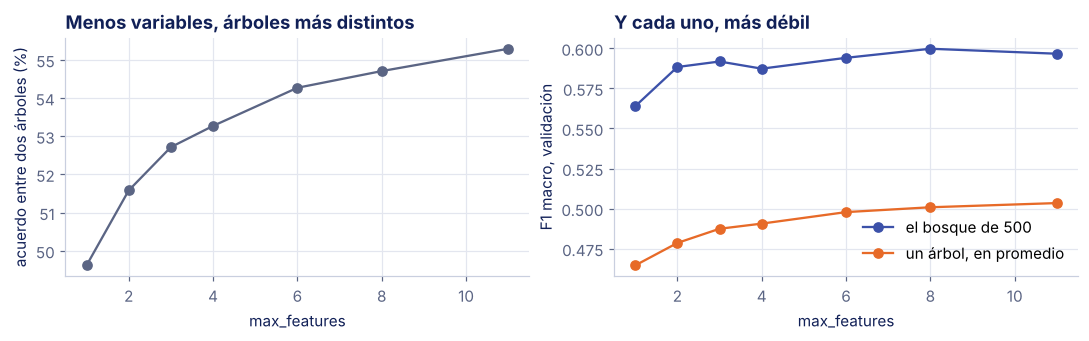

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
ax1.plot(sorteo.index, sorteo["acuerdo entre árboles"] * 100, "o-", color=GRIS)
ax1.set_xlabel("max_features")
ax1.set_ylabel("acuerdo entre dos árboles (%)")
ax1.set_title("Menos variables, árboles más distintos")
ax2.plot(sorteo.index, sorteo["F1 del bosque"], "o-", color=AZUL_MEDIO, label="el bosque de 500")
ax2.plot(sorteo.index, sorteo["F1 de un árbol"], "o-", color=NARANJA, label="un árbol, en promedio")
ax2.set_xlabel("max_features")
ax2.set_ylabel("F1 macro, validación")
ax2.set_title("Y cada uno, más débil")
ax2.legend()
plt.tight_layout()
plt.show()

### ¿Qué variables importan?

`feature_importances_` es la **MDI** (*mean decrease in impurity*): cuánto reduce la impureza cada variable, sumado sobre todos los nodos donde se usa y promediado en los árboles. Se calcula con los datos de entrenamiento. La **importancia por permutación** mide otra cosa: cuánto baja el F1 en validación al barajar una variable, que rompe su relación con la clase (diapositiva 52). Para ver la diferencia agregamos una columna de **ruido puro**: números normales sin ninguna relación con la calidad. Tarda menos de un minuto.

In [24]:
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(SEMILLA)
X_ruido = X_e.copy()
X_ruido["ruido"] = rng.normal(size=len(X_ruido))

bosque_ruido = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1).fit(X_ruido, y_e)
mdi = pd.Series(bosque_ruido.feature_importances_, index=X_ruido.columns)
permutacion = []
for a, b in pliegues.split(X_ruido, y_e, g_e):
    rf = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1).fit(X_ruido.iloc[a], y_e.iloc[a])
    r = permutation_importance(rf, X_ruido.iloc[b], y_e.iloc[b], scoring="f1_macro", n_repeats=10, random_state=0, n_jobs=-1)
    permutacion.append(r.importances_mean)
importancia = pd.DataFrame({"MDI": mdi, "permutación, validación": np.mean(permutacion, axis=0)})
importancia["lugar MDI"] = importancia["MDI"].rank(ascending=False).astype(int)
importancia["lugar permutación"] = importancia["permutación, validación"].rank(ascending=False).astype(int)
importancia.sort_values("MDI", ascending=False).round(4)

,MDI,"permutación, validación",lugar MDI,lugar permutación
alcohol,0.1466,0.1304,1,1
sulphates,0.1222,0.0947,2,2
volatile acidity,0.0969,0.0337,3,3
total sulfur dioxide,0.0888,0.0144,4,4
density,0.0850,0.0048,5,7
chlorides,0.0746,0.0003,6,10
fixed acidity,0.0675,0.0069,7,5
citric acid,0.0669,0.0067,8,6
pH,0.0658,-0.0029,9,11
residual sugar,0.0647,0.0047,10,8


**Lectura.** Con MDI, el ruido queda en el lugar 11 de 12, con 0.061: casi lo mismo que free sulfur dioxide, residual sugar o pH, que sí son medidas del vino. Un número continuo, con un valor distinto en cada vino, ofrece muchos cortes posibles, y los árboles profundos lo usan para memorizar casos sueltos. Con permutación en validación, el ruido queda en el último lugar, con −0.004: barajarlo no cambia nada. Solo alcohol, sulphates y volatile acidity pesan claramente; las demás quedan por debajo de 0.015. Strobl et al. (2007) describen este sesgo de la MDI, y la guía de scikit-learn recomienda la permutación.

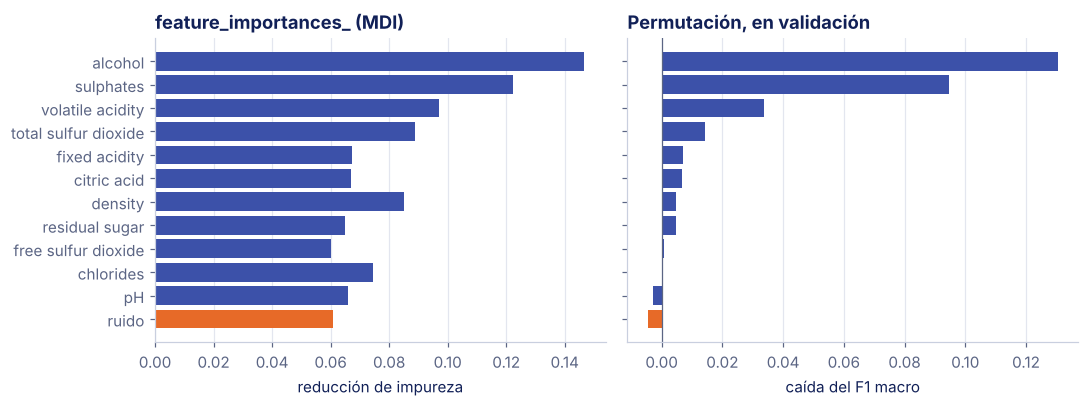

In [25]:
orden = importancia["permutación, validación"].sort_values().index
colores = [NARANJA if v == "ruido" else AZUL_MEDIO for v in orden]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
ax1.barh(orden, importancia.loc[orden, "MDI"], color=colores)
ax1.set_title("feature_importances_ (MDI)")
ax1.set_xlabel("reducción de impureza")
ax2.barh(orden, importancia.loc[orden, "permutación, validación"], color=colores)
ax2.axvline(0, color=GRIS, linewidth=0.8)
ax2.set_title("Permutación, en validación")
ax2.set_xlabel("caída del F1 macro")
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### ¿Cuántos árboles?

En random forest, agregar árboles no sobreajusta: el error converge (Breiman, 2001). Pero, ¿cuántos hacen falta? En cada pliegue entrenamos un bosque de 500 y evaluamos el promedio de sus primeros $L$ árboles (diapositiva 61). Después repetimos con 10 semillas para ver cuánto cambia el resultado con pocos árboles.

In [26]:
inicio = time.perf_counter()
Ls = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500]
curva = {L: [] for L in Ls}
for a, b in pliegues.split(X_e, y_e, g_e):
    rf = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1).fit(X_e.iloc[a], y_e.iloc[a])
    acumulado = np.cumsum(por_arbol(rf, X_e.iloc[b]), axis=0)          # suma de las probabilidades de los primeros L
    for L in Ls:
        curva[L].append(f1_score(y_e.iloc[b], CLASES[acumulado[L - 1].argmax(axis=1)], average="macro"))
tamano = pd.DataFrame({"F1 macro, validación": {L: np.mean(v) for L, v in curva.items()},
                       "desv. est.": {L: np.std(v) for L, v in curva.items()}})
tamano.index.name = "árboles"

semillas = {}
for L in [5, 20, 100]:
    r = [cross_validate(RandomForestClassifier(n_estimators=L, random_state=s, n_jobs=-1), X_e, y_e, groups=g_e,
                        cv=pliegues, scoring="f1_macro")["test_score"].mean() for s in range(10)]
    semillas[L] = {"mínimo": np.min(r), "máximo": np.max(r)}
print(f"{time.perf_counter() - inicio:.0f} s")
for L, d in semillas.items():
    print(f"Con {L:3d} árboles y 10 semillas, el F1 de validación va de {d['mínimo']:.3f} a {d['máximo']:.3f}")
tamano.round(3).T

22 s
Con   5 árboles y 10 semillas, el F1 de validación va de 0.505 a 0.561
Con  20 árboles y 10 semillas, el F1 de validación va de 0.552 a 0.594
Con 100 árboles y 10 semillas, el F1 de validación va de 0.583 a 0.597


árboles,1,2,3,5,7,10,15,20,30,50,75,100,150,200,300,400,500
"F1 macro, validación",0.480,0.443,0.491,0.519,0.546,0.560,0.560,0.577,0.586,0.587,0.591,0.592,0.591,0.590,0.581,0.586,0.592
desv. est.,0.031,0.029,0.032,0.031,0.029,0.014,0.011,0.028,0.044,0.032,0.035,0.043,0.035,0.042,0.052,0.046,0.043


**Lectura.** Con un árbol, 0.480; con dos, 0.443, porque cuando discrepan el empate se resuelve por la primera clase; con tres, 0.491. Sube rápido hasta 0.577 con 20 y llega a 0.592 con 100; de 100 a 500 cambia menos de 0.01, muy por debajo de la desviación entre pliegues. Con pocos árboles importa la semilla: con 5, el F1 va de 0.505 a 0.561; con 100, de 0.583 a 0.597. La regla de «tantos clasificadores como clases» (Bonab y Can, 2016) supone clasificadores independientes; aquí serían 3 árboles, con 0.491.

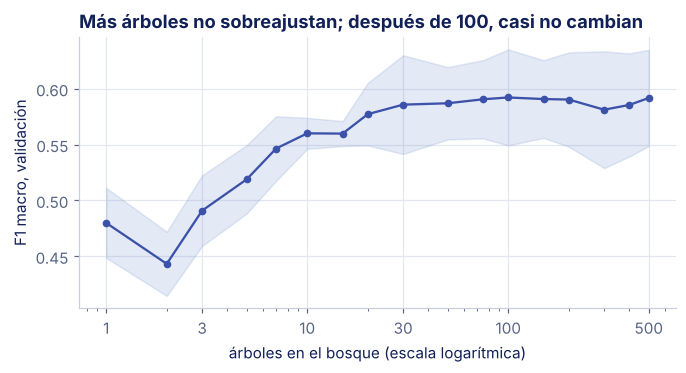

In [27]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.fill_between(tamano.index, tamano.iloc[:, 0] - tamano.iloc[:, 1], tamano.iloc[:, 0] + tamano.iloc[:, 1], color=AZUL, alpha=0.2)
ax.plot(tamano.index, tamano.iloc[:, 0], "o-", color=AZUL_MEDIO, markersize=4)
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100, 500], ["1", "3", "10", "30", "100", "500"])
ax.set_xlabel("árboles en el bosque (escala logarítmica)")
ax.set_ylabel("F1 macro, validación")
ax.set_title("Más árboles no sobreajustan; después de 100, casi no cambian")
plt.show()

### Las variantes

Bagging y random forest no son las únicas formas de sortear (diapositiva 53). **Extra-Trees** (Geurts et al., 2006) sortea en cada nodo las variables y también el umbral, sin bootstrap. Los **subespacios aleatorios** (Ho, 1998) sortean las variables una sola vez por árbol, y los **parches aleatorios** (Louppe y Geurts, 2012), filas y variables por árbol. Las dos últimas se arman con `BaggingClassifier`.

In [28]:
from sklearn.ensemble import ExtraTreesClassifier

arbol_base = DecisionTreeClassifier(random_state=0)
variantes = {
    "bagging": BaggingClassifier(arbol_base, n_estimators=500, random_state=0, n_jobs=-1),
    "random forest": RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1),
    "Extra-Trees": ExtraTreesClassifier(n_estimators=500, random_state=0, n_jobs=-1),
    "subespacios aleatorios": BaggingClassifier(arbol_base, n_estimators=500, max_features=0.5, bootstrap=False,
                                                random_state=0, n_jobs=-1),
    "parches aleatorios": BaggingClassifier(arbol_base, n_estimators=500, max_features=0.5, max_samples=0.5,
                                            random_state=0, n_jobs=-1),
}


def evaluar(modelo):
    r = cross_validate(modelo, X_e, y_e, groups=g_e, cv=pliegues, scoring="f1_macro", return_train_score=True)
    pred = modelo.fit(X_e, y_e).predict(X_p)
    return {"F1 macro, validación": r["test_score"].mean(), "desv. est.": r["test_score"].std(),
            "F1 macro, entrenamiento": r["train_score"].mean(), "F1 macro, prueba": f1_score(y_p, pred, average="macro")}


inicio = time.perf_counter()
tabla_variantes = pd.DataFrame({nombre: evaluar(m) for nombre, m in variantes.items()}).T
print(f"{time.perf_counter() - inicio:.0f} s")
tabla_variantes.round(3)

29 s


,"F1 macro, validación",desv. est.,"F1 macro, entrenamiento","F1 macro, prueba"
bagging,0.592,0.039,1.000,0.618
random forest,0.592,0.043,1.000,0.621
Extra-Trees,0.573,0.053,1.000,0.642
subespacios aleatorios,0.555,0.044,1.000,0.611
parches aleatorios,0.557,0.056,0.996,0.538


**Lectura.** En validación van de 0.555 a 0.592, con desviaciones entre pliegues de 0.04 a 0.06: empatan. Extra-Trees saca la mejor prueba (0.642), pero la prueba se ve una sola vez y no sirve para elegir; en validación está por debajo de bagging y random forest. Todas memorizan el entrenamiento (F1 de 1.000, salvo los parches, que ven la mitad de las filas): en un bosque, lo que cuenta es la validación.

---

## 5. Stacking

### Dentro de la muestra contra fuera del pliegue

El stacking entrena un **metamodelo** con las predicciones de los modelos base (diapositivas 55 y 56). El paso 2 del algoritmo construye esos datos aplicando cada modelo base a los mismos ejemplos con que se entrenó. El problema: un modelo que memoriza da predicciones perfectas en sus datos de entrenamiento, y el metamodelo aprende a confiar en él. La solución (Wolpert, 1992) son las predicciones **fuera del pliegue** que ya calculamos en la sección 2: cada vino recibe las de modelos que no lo vieron (diapositiva 57).

El metamodelo es una regresión logística sobre las 15 probabilidades de los cinco modelos (3 por modelo). Comparamos las dos versiones, con los cinco de la unidad 4 y agregando el árbol completo, que memoriza.

In [29]:
def p_completo(X_a, y_a, X_b):
    return DecisionTreeClassifier(random_state=0).fit(X_a, y_a).predict_proba(X_b)


P_dentro = probas(X_e, y_e, g_e, X_e)                 # cada modelo, sobre sus propios datos de entrenamiento
P_dentro["árbol completo"] = p_completo(X_e, y_e, X_e)
P_prueba_6 = dict(P_prueba, **{"árbol completo": p_completo(X_e, y_e, X_p)})
P_oof_6 = dict(P_oof, **{"árbol completo": np.zeros((len(X_e), 3))})
for a, b in pliegues.split(X_e, y_e, g_e):
    P_oof_6["árbol completo"][b] = p_completo(X_e.iloc[a], y_e.iloc[a], X_e.iloc[b])
print("Exactitud dentro de la muestra:", {m: round(accuracy_score(y_e, CLASES[P.argmax(axis=1)]), 3) for m, P in P_dentro.items()})


def apila(P, base):
    return np.hstack([P[m] for m in base])


stack_prueba, pesos = {}, {}
for etiqueta, base in [("los cinco", MODELOS), ("los cinco + árbol completo", MODELOS + ["árbol completo"])]:
    for modo, P_entrena in [("dentro de la muestra", P_dentro), ("fuera del pliegue", P_oof_6)]:
        meta = LogisticRegression(max_iter=5000).fit(apila(P_entrena, base), y_e)
        pred = meta.predict(apila(P_prueba_6, base))
        stack_prueba[(etiqueta, modo)] = f1_score(y_p, pred, average="macro")
        # peso de cada modelo: el coeficiente medio de P_m(k) en el puntaje de la clase k
        pesos[(etiqueta, modo)] = {m: np.mean([meta.coef_[k, 3 * i + k] for k in range(3)]) for i, m in enumerate(base)}
print(pd.Series(stack_prueba).unstack().round(3).rename_axis("F1 macro en prueba"))
pd.DataFrame(pesos).round(2)

Exactitud dentro de la muestra: {'logística': 0.642, 'árbol elegido': 0.745, 'Naive Bayes': 0.618, 'kNN': 1.0, 'SVM': 0.792, 'árbol completo': 1.0}
                            dentro de la muestra  fuera del pliegue
F1 macro en prueba                                                 
los cinco                                  0.597              0.573
los cinco + árbol completo                 0.488              0.567


los cinco                    \
               dentro de la muestra fuera del pliegue   
logística                      0.13              0.46   
árbol elegido                  0.52              0.61   
Naive Bayes                    0.14              0.18   
kNN                            3.25              0.54   
SVM                            0.46              0.46   
árbol completo                  NaN               NaN   

               los cinco + árbol completo                    
                     dentro de la muestra fuera del pliegue  
logística                            0.14              0.47  
árbol elegido                        0.42              0.50  
Naive Bayes                          0.16              0.19  
kNN                                  1.85              0.48  
SVM                                  0.32              0.37  
árbol completo                       1.85              0.18

**Lectura.** Dentro de la muestra, el kNN (con pesos por distancia) y el árbol completo aciertan el 100 % de su entrenamiento, y el metamodelo les cree: con los cinco, el kNN recibe un peso de 3.25 contra 0.6 o menos de los demás; con el árbol completo, los dos se reparten el peso, 1.85 cada uno. Lo que pase después depende de quién memorizó. El kNN generaliza bien, y el stacking dentro de la muestra queda en 0.597, casi una copia del kNN. El árbol completo generaliza mal, y el ensamble se hunde a 0.488, como el árbol solo. Fuera del pliegue, el árbol completo recibe el peso más bajo (0.18) y el ensamble queda en 0.567.

Para comparar el stacking con lo demás, su validación tiene que ser **anidada**: en cada pliegue externo, las predicciones fuera del pliegue se calculan con pliegues internos del entrenamiento de ese pliegue. Tarda unos segundos.

In [30]:
inicio = time.perf_counter()
anidada = {"dentro de la muestra": [], "fuera del pliegue": []}
for a, b in pliegues.split(X_e, y_e, g_e):
    Xa, ya, ga = X_e.iloc[a], y_e.iloc[a], g_e.iloc[a]
    Pb = probas(Xa, ya, ga, X_e.iloc[b])
    Pa_dentro = probas(Xa, ya, ga, Xa)
    Pa_oof = {m: np.zeros((len(Xa), 3)) for m in MODELOS}
    for aa, bb in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(Xa, ya, ga):
        for m, P in probas(Xa.iloc[aa], ya.iloc[aa], ga.iloc[aa], Xa.iloc[bb]).items():
            Pa_oof[m][bb] = P
    for modo, P_entrena in [("dentro de la muestra", Pa_dentro), ("fuera del pliegue", Pa_oof)]:
        meta = LogisticRegression(max_iter=5000).fit(apila(P_entrena, MODELOS), ya)
        anidada[modo].append(f1_score(y_e.iloc[b], meta.predict(apila(Pb, MODELOS)), average="macro"))
print(f"{time.perf_counter() - inicio:.0f} s")
pd.DataFrame({modo: {"F1 macro, validación": np.mean(v), "desv. est.": np.std(v)} for modo, v in anidada.items()}).T.round(3)

12 s


,"F1 macro, validación",desv. est.
dentro de la muestra,0.574,0.030
fuera del pliegue,0.560,0.019


**Lectura.** Con los cinco, el stacking fuera del pliegue saca 0.560 en validación, por debajo de cada uno de ellos, y la versión dentro de la muestra, 0.574. Las dos diferencias caben en la desviación entre pliegues. El stacking no tiene qué combinar: los cinco se equivocan juntos (sección 2). Y la fuga no siempre se nota en el resultado; se nota en los pesos, y basta un modelo base que memorice y generalice mal para que el ensamble se hunda.

`StackingClassifier` hace esto mismo: su parámetro `cv` decide cómo se calculan las predicciones fuera del pliegue. Por omisión usa `StratifiedKFold`, que no conoce los grupos; con duplicados hay que pasarle una lista de cortes agrupados, como hicimos con el SVM calibrado.

---

## 6. Los ensambles en el vino, en una tabla

La tabla de la unidad 4 (notebook 16) con los ensambles de hoy, con el mismo protocolo (diapositiva 63). Tarda alrededor de medio minuto.

In [31]:
inicio = time.perf_counter()
unidad = {
    "regresión logística (11)": make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)),
    "árbol elegido (13)": DecisionTreeClassifier(random_state=0, max_depth=6, min_samples_leaf=5),
    "Naive Bayes (14)": GaussianNB(),
    "kNN (15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=51, weights="distance", p=1)),
    "SVM (16)": make_pipeline(StandardScaler(), SVC(C=100, gamma=0.03)),
    "árbol completo": DecisionTreeClassifier(random_state=0),
}
tabla = pd.DataFrame({nombre: evaluar(m) for nombre, m in unidad.items()}).T
for nombre in ["bagging", "random forest", "Extra-Trees"]:
    tabla.loc[f"{nombre}, 500 árboles"] = tabla_variantes.loc[nombre]
for nombre in ["votación dura", "votación suave"]:
    tabla.loc[nombre] = votacion.loc[nombre, ["F1 macro, validación", "desv. est.", "F1 macro, prueba"]]
tabla.loc["stacking, fuera del pliegue"] = pd.Series({"F1 macro, validación": np.mean(anidada["fuera del pliegue"]),
                                                     "desv. est.": np.std(anidada["fuera del pliegue"]),
                                                     "F1 macro, prueba": stack_prueba[("los cinco", "fuera del pliegue")]})
print(f"{time.perf_counter() - inicio:.0f} s")
tabla.round(3)

2 s


,"F1 macro, validación",desv. est.,"F1 macro, entrenamiento","F1 macro, prueba"
regresión logística (11),0.562,0.022,0.592,0.573
árbol elegido (13),0.584,0.022,0.743,0.551
Naive Bayes (14),0.579,0.044,0.592,0.596
kNN (15),0.566,0.041,1.000,0.584
SVM (16),0.582,0.027,0.807,0.576
árbol completo,0.551,0.038,1.000,0.484
"bagging, 500 árboles",0.592,0.039,1.000,0.618
"random forest, 500 árboles",0.592,0.043,1.000,0.621
"Extra-Trees, 500 árboles",0.573,0.053,1.000,0.642
votación dura,0.588,0.022,NaN,0.595


**Lectura.** Los ensambles de árboles arreglan al árbol: el árbol completo saca 0.551 en validación y 0.484 en prueba; bagging, random forest y Extra-Trees, de 0.573 a 0.592 en validación y de 0.618 a 0.642 en prueba. Contra el mejor modelo de la unidad 4, en cambio, la ganancia en validación (0.592 contra 0.584 del árbol elegido) cabe en la desviación entre pliegues, y en prueba los bosques le sacan de 0.02 a 0.05 a Naive Bayes. Combinar a los cinco por votación o stacking no ayuda: se equivocan juntos.

Mañana, en esta misma tabla: AdaBoost, gradient boosting, XGBoost, LightGBM y CatBoost. La Práctica 4 repite estas comparaciones con la deserción escolar.

---

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de Claude (Anthropic) para estructurar el contenido a partir de las diapositivas de la sesión, redactar el texto explicativo y preparar los ejemplos. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.

### Referencias

- Dietterich, T. G. (2000). Ensemble methods in machine learning. En *Multiple Classifier Systems*, LNCS 1857, 1-15. Springer.
- Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24(2), 123-140.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241-259.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*, 2a ed., capítulos 8, 15 y 16. Springer.
- Kuncheva, L. I. (2014). *Combining Pattern Classifiers: Methods and Algorithms*, 2a ed. Wiley.
- Mitchell, T. M. (1997). *Machine Learning*, capítulo 6: Bayesian Learning. McGraw-Hill.
- Minka, T. P. (2000). Bayesian model averaging is not model combination. MIT Media Lab.
- Monteith, K., Carroll, J. L., Seppi, K., & Martinez, T. (2011). Turning Bayesian model averaging into Bayesian model combination. En *IJCNN 2011*, 2657-2663.
- Ho, T. K. (1998). The random subspace method for constructing decision forests. *IEEE TPAMI*, 20(8), 832-844.
- Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning*, 63(1), 3-42.
- Louppe, G., & Geurts, P. (2012). Ensembles on random patches. En *ECML PKDD 2012*, 346-361.
- Bonab, H. R., & Can, F. (2016). A theoretical framework on the ideal number of classifiers for online ensembles in data streams. En *CIKM 2016*. ACM.
- Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures: Illustrations, sources and a solution. *BMC Bioinformatics*, 8, 25.
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 2022, Datasets and Benchmarks Track*. [arXiv:2207.08815](https://arxiv.org/abs/2207.08815)
- VanderPlas, J. (2022). *Python Data Science Handbook*, 2a ed. O'Reilly. [Capítulo 44: In-Depth: Decision Trees and Random Forests](https://jakevdp.github.io/PythonDataScienceHandbook/05.08-random-forests.html)
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547-553.
- [scikit-learn: Ensembles](https://scikit-learn.org/stable/modules/ensemble.html) · [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) · [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html) · [VotingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html) · [StackingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html) · [Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)